In [ ]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import importlib

ev = importlib.import_module("evaluate_model")
predict = importlib.import_module("predict")

In [2]:
# Test scores and metrics
threshold = predict.load_info()["threshold"]
y_true, proba = ev.get_test_scores()

metrics = ev.get_metrics(y_true, proba, threshold)
pd.Series(metrics)

c:\Users\praja\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator FunctionTransformer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\praja\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\praja\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.9.1 when using version 1.9.0. This might lead to brea

threshold             0.500000
precision             0.001859
recall                0.395833
f1                    0.003701
roc_auc               0.488012
pr_auc                0.001796
true_negative     29505.000000
false_positive    20399.000000
false_negative       58.000000
true_positive        38.000000
dtype: float64

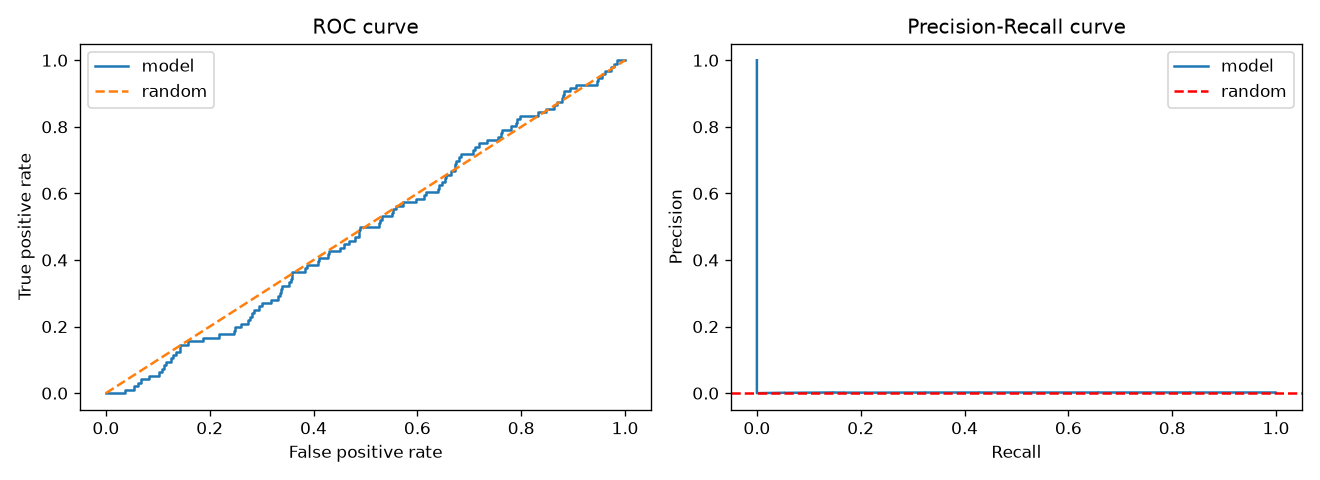

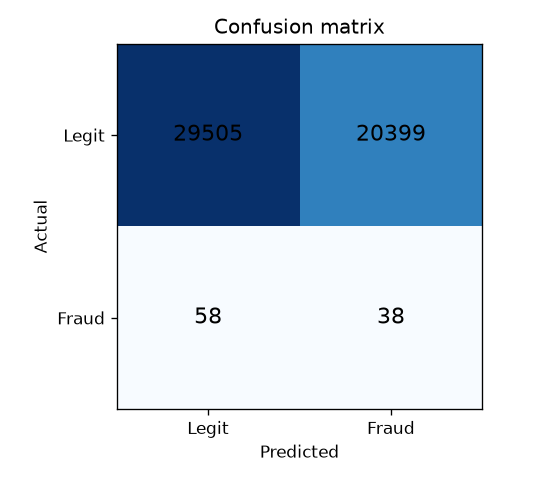

In [3]:
# Curves and confusion matrix
ev.save_plots(y_true, proba, threshold)
display(Image("../../reports/figures/20_roc_pr_curves.png"))
display(Image("../../reports/figures/21_confusion_matrix.png"))

In [4]:
# What happens with a different threshold?
rows = []
for t in [0.3, 0.4, 0.45, 0.5, 0.55, 0.6]:
    m = ev.get_metrics(y_true, proba, t)
    rows.append({"threshold": t, "precision": round(m["precision"], 4),
                 "recall": round(m["recall"], 3),
                 "flagged": m["true_positive"] + m["false_positive"],
                 "fraud_caught": m["true_positive"]})
pd.DataFrame(rows)

,threshold,precision,recall,flagged,fraud_caught
0,0.30,0.0019,0.969,48550,93
1,0.40,0.0019,0.802,39508,77
2,0.45,0.0019,0.594,30738,57
3,0.50,0.0019,0.396,20437,38
4,0.55,0.0015,0.177,11698,17
5,0.60,0.0014,0.083,5674,8


In [5]:
# Probability of legit vs fraud
plt.figure(figsize=(7, 4))
plt.hist(proba[y_true == 0], bins=40, alpha=0.6, label="Legit", density=True)
plt.hist(proba[y_true == 1], bins=40, alpha=0.6, label="Fraud", density=True)
plt.xlabel("Fraud probability")
plt.legend()
plt.show()

C:\Users\praja\AppData\Local\Temp\ipykernel_11200\2862977889.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Conclusions
- ROC-AUC is 0.49 and PR-AUC is 0.0018 (random guessing gives 0.0019). The model is **not better than random**.
- At threshold 0.5 it catches 38 of 96 frauds, but flags about 20,400 normal payments.
  Precision is only 0.19%.
- A lower threshold catches more fraud but flags almost every payment. A higher threshold
  catches almost nothing. No threshold works well.
- The histogram shows legit and fraud probabilities overlapping almost completely.
- Reason: the data has almost no link between features and fraud. The model is not broken.